# Stage 10: LangGraph Fundamentals & Stateful Multi-Actor Systems
## Module 06: LLM-Powered Chatbot with Reducers and Pregel Streaming

This notebook provides the production reference implementation for **SuperBot**, an LLM-driven conversational workflow. 

### Engineering Objectives:
1. Implement a state schema using `Annotated` with the `add_messages` reducer to ensure append-only conversational history.
2. Initialize multi-provider LLM inference (Groq LPU high-throughput engine with fallback mechanisms).
3. Construct, wire, and compile a `StateGraph` linking `START -> super_bot -> END`.
4. Demonstrate synchronous invocation (`.invoke()`) and validate message accumulation invariants.
5. Contrast real-time Pregel streaming modes: `stream_mode="updates"` vs `stream_mode="values"`.

In [1]:
import os
from typing import Dict, Any, List, Sequence
from typing_extensions import TypedDict, Annotated
from dotenv import load_dotenv

from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langchain_groq import ChatGroq
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from IPython.display import Image, display

# Load environment variables
load_dotenv()
print("All core dependencies and modules imported successfully.")

All core dependencies and modules imported successfully.


In [2]:
# Initialize Primary LLM via Groq LPU
groq_api_key = os.getenv("GROQ_API_KEY")
openai_api_key = os.getenv("OPENAI_API_KEY")

if groq_api_key:
    llm = ChatGroq(
        model="openai/gpt-oss-20b",
        temperature=0.0,
        max_tokens=150
    )
    provider_name = "Groq LPU (openai/gpt-oss-20b)"
elif openai_api_key:
    llm = ChatOpenAI(
        model="gpt-4o-mini",
        temperature=0.0,
        max_tokens=150
    )
    provider_name = "OpenAI (gpt-4o-mini)"
else:
    raise RuntimeError("Neither GROQ_API_KEY nor OPENAI_API_KEY is configured in the environment.")

# Test baseline model invocation
test_response = llm.invoke([HumanMessage(content="Ping")])
assert isinstance(test_response, AIMessage), "LLM did not return an AIMessage instance."
assert len(test_response.content) > 0, "LLM returned an empty response string."

print(f"Active LLM provider: {provider_name}")
print(f"Smoke test response preview: '{test_response.content.strip()[:60]}...'")

Active LLM provider: Groq LPU (openai/gpt-oss-20b)
Smoke test response preview: 'Pong!...'


In [3]:
class ChatState(TypedDict):
    """State schema for multi-turn conversational agents.
    
    The 'messages' field utilizes the 'add_messages' reducer:
    - Merges new messages into the existing conversation history.
    - Appends items by default, preventing shallow state overwriting.
    - Updates existing messages when message IDs match.
    """
    messages: Annotated[Sequence[BaseMessage], add_messages]

# Verify state annotation metadata
state_annotations = ChatState.__annotations__
assert "messages" in state_annotations, "State schema missing 'messages' key."
print("State schema defined with 'add_messages' reducer.")

State schema defined with 'add_messages' reducer.


In [4]:
def super_bot(state: ChatState) -> Dict[str, List[BaseMessage]]:
    """Conversational worker node processing accumulated messages via the LLM.
    
    Args:
        state: Current conversational state containing message sequence.
        
    Returns:
        Dictionary update containing the newly generated AIMessage.
    """
    inbound_messages = state.get("messages", [])
    assert len(inbound_messages) > 0, "Node received an empty message history."
    
    # Invoke model with the entire historical message context
    ai_response = llm.invoke(inbound_messages)
    
    # Return delta update; add_messages handles appending automatically
    return {"messages": [ai_response]}

print("Worker node 'super_bot' successfully defined.")

Worker node 'super_bot' successfully defined.


In [5]:
# Instantiate StateGraph with ChatState schema
builder = StateGraph(ChatState)

# Register node
builder.add_node("super_bot", super_bot)

# Define linear edge wiring
builder.add_edge(START, "super_bot")
builder.add_edge("super_bot", END)

# Compile into an executable Pregel application
app = builder.compile()
print("Graph successfully compiled into executable application.")

Graph successfully compiled into executable application.


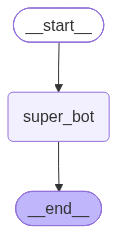

[Visualization] Graph topology successfully rendered as PNG.


In [6]:
try:
    display(Image(app.get_graph().draw_mermaid_png()))
    print("[Visualization] Graph topology successfully rendered as PNG.")
except Exception as exc:
    print(f"[Visualization Warning] PNG rendering unavailable: {exc}")
    print("[Visualization Fallback] Raw Mermaid definition:")
    print(app.get_graph().draw_mermaid())

In [7]:
# Prepare initial conversational input
initial_input = {
    "messages": [HumanMessage(content="Hi, my name is Alex and I am studying distributed RAG systems.")]
}

print("Executing synchronous graph invocation:")
print("-" * 60)
final_state = app.invoke(initial_input)
print("-" * 60)

# Validate state accumulation invariants
accumulated_messages = final_state["messages"]
assert len(accumulated_messages) == 2, f"Expected 2 messages, found {len(accumulated_messages)}"
assert isinstance(accumulated_messages[0], HumanMessage), "First message must be HumanMessage."
assert isinstance(accumulated_messages[1], AIMessage), "Second message must be AIMessage."

print(f"Total accumulated messages: {len(accumulated_messages)}")
print(f"User: {accumulated_messages[0].content}")
print(f"SuperBot: {accumulated_messages[1].content.strip()}")

Executing synchronous graph invocation:
------------------------------------------------------------


------------------------------------------------------------
Total accumulated messages: 2
User: Hi, my name is Alex and I am studying distributed RAG systems.
SuperBot: Hi Alex! 👋 It’s great to meet someone diving into distributed Retrieval‑Augmented Generation (RAG) systems. What aspects are you most excited about—scaling the retrieval layer, orchestrating multiple LLMs, or maybe the data‑flow and consistency challenges? Feel free to share any specific questions or projects you’re working on!


In [8]:
# Stream execution using stream_mode='updates' (node deltas only)
stream_input = {
    "messages": [HumanMessage(content="What are the three main components of a standard RAG pipeline? Keep it brief.")]
}

print("Streaming graph events (stream_mode='updates'):")
print("=" * 60)

event_count = 0
for event in app.stream(stream_input, stream_mode="updates"):
    event_count += 1
    node_name = list(event.keys())[0]
    node_output = event[node_name]
    assert "messages" in node_output, "Node output delta missing 'messages' key."
    emitted_msg = node_output["messages"][0]
    assert isinstance(emitted_msg, AIMessage), "Emitted delta message must be an AIMessage."
    
    print(f"[Event {event_count}] Node '{node_name}' emitted {len(node_output['messages'])} delta message(s):")
    print(f"Response: {emitted_msg.content.strip()[:100]}...")

print("=" * 60)
assert event_count == 1, f"Expected 1 superstep event for linear graph, got {event_count}"
print("Updates streaming verified successfully.")

Streaming graph events (stream_mode='updates'):


[Event 1] Node 'super_bot' emitted 1 delta message(s):
Response: **Three core parts of a standard RAG pipeline**

1. **Retrieval** – query the...
Updates streaming verified successfully.


In [9]:
# Stream execution using stream_mode='values' (full state snapshots)
values_input = {
    "messages": [HumanMessage(content="Give me a one-sentence tip for optimizing vector search latency.")]
}

print("Streaming graph snapshots (stream_mode='values'):")
print("=" * 60)

snapshot_count = 0
for snapshot in app.stream(values_input, stream_mode="values"):
    snapshot_count += 1
    current_messages = snapshot["messages"]
    print(f"[Snapshot {snapshot_count}] Total messages in state: {len(current_messages)}")
    for idx, msg in enumerate(current_messages, start=1):
        role = "User" if isinstance(msg, HumanMessage) else "SuperBot"
        print(f"  {idx}. {role}: {msg.content.strip()[:60]}...")

print("=" * 60)
# In stream_mode='values', step 1 yields initial input, step 2 yields state after super_bot
assert snapshot_count == 2, f"Expected 2 snapshots (initial + after node), got {snapshot_count}"
print("Values streaming verified successfully.")

Streaming graph snapshots (stream_mode='values'):
[Snapshot 1] Total messages in state: 1
  1. User: Give me a one-sentence tip for optimizing vector search late...


[Snapshot 2] Total messages in state: 2
  1. User: Give me a one-sentence tip for optimizing vector search late...
  2. SuperBot: Use an approximate nearest‑neighbor index (e.g.,...
Values streaming verified successfully.


In [10]:
# Production Integrity & Architectural Regression Test
print("Executing comprehensive regression test...")

# Test multi-turn message retention simulation
multi_turn_state = app.invoke({
    "messages": [
        HumanMessage(content="Remember the secret code: EPSILON-42."),
        AIMessage(content="Understood. I have recorded the code EPSILON-42."),
        HumanMessage(content="What was the secret code I gave you?")
    ]
})

final_msgs = multi_turn_state["messages"]
assert len(final_msgs) == 4, f"Expected 4 messages in multi-turn state, got {len(final_msgs)}"
assert "EPSILON-42" in final_msgs[-1].content or "EPSILON" in final_msgs[-1].content, "SuperBot failed to recall historical context."

print("Multi-turn context retention test passed.")
print("All production assertions passed successfully.")

Executing comprehensive regression test...


Multi-turn context retention test passed.
All production assertions passed successfully.
